# 🔬 BLOQUE 1: Análisis Exploratorio de Datos (EDA), Diagnóstico de Características y Multicolinealidad
### Tesis: *Predicción de la Ley Mineral de Venta Mediante Redes Neuronales Artificiales para Minimizar Pérdidas Económicas*
**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Carpeta del Módulo:** `./BLOQUE_1/`  
* **Entregable Oficial:** Cuaderno Técnico de Pre-Modelado y Selección de Características (`01_eda_caracteristicas.ipynb`)  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Todo el análisis estadístico previo a la modelación)

---

## 🎯 Objetivos Específicos del Bloque 1
1. **Caracterización Univariada y Dispersión:** Cuantificar medidas de tendencia central ($\mu, 	ilde{x}$, media truncada), dispersión muestral ($s, s^2$) y poblacional ($\sigma, \sigma^2$), rango intercuartílico ($	ext{IQR}$) y **Coeficiente de Variación ($	ext{CV}\%$)** sobre los $N = 24$ balances mensuales auditados.
2. **Contraste de Varianzas y Descomposición del Error Histórico:** Fundamentar el escalado Z-score obligatorio mediante el contraste de varianzas ($s^2_{	ext{CuT}} / s^2_{	ext{CuS}} = 61.6	imes$) y descomponer el $	ext{MSE}$ histórico ($0.1350\,(\%	ext{Cu})^2$) en sesgo sistemático ($85.83\%$) y varianza residual ($14.17\%$).
3. **Estructura de Covarianza Muestral y Correlaciones:** Computar la matriz de covarianza muestral ($5 	imes 5$) y contrastar correlación de Pearson ($r$), Spearman ($ho$) e Información Mutua ($	ext{MI}$), demostrando el efecto de apalancamiento (*leverage*) de los pulsos extremos de Octubre y Noviembre 2023.
4. **Evaluación Rigurosa de Normalidad:** Aplicar el test de **Shapiro-Wilk** ($lpha = 0.05$) complementado con histogramas, curvas KDE y gráficos Q-Q normales para diagnosticar el rechazo gaussiano por asimetría geológica.
5. **Detección y Justificación Geometalúrgica de Outliers:** Evaluar atípicos univariados (Tukey) y multivariados mediante la distancia de **Mahalanobis** ($D_M^2$ frente a $\chi^2_{2, 0.95} = 5.9915$), justificando su retención geológica total.
6. **Auditoría de Dependencia Serial (ACF):** Verificar que el sesgo empírico es ruido blanco puro ($r_1 = -0.0866$), validando **LOOCV** como protocolo maestro, y documentar la persistencia de $	ext{CuT}$ ($r_1 = +0.4467$) para motivar la sensibilidad por *Buffered-LOOCV*.
7. **Auditoría de Multicolinealidad (VIF con Intercepto):** Evaluar el Factor de Inflación de la Varianza con constante agregada, reportando las variables explicativas limpias ($	ext{VIF} = 1.8045 < 5.0$) y demostrando la explosión colineal si se introduce $	ext{CuIn}$ ($	ext{VIF} > 4{,}000$).

In [1]:
# Importación de librerías científicas y configuración estética
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import acf
from sklearn.feature_selection import mutual_info_regression

# Configuración estética profesional institucional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.dpi'] = 150

print("✅ Entorno científico y de visualización configurado exitosamente.")

✅ Entorno científico y de visualización configurado exitosamente.


---
## 1. Carga del Dataset Maestro Auditado ($N = 24$) y Variables Derivadas

Se carga el archivo `DATASET_AUDITADO_N24.csv` certificado en el **Bloque 0** ($N = 24$ balances mensuales continuos con leyes estandarizadas a 2 decimales en $\%	ext{Cu}$).

Se computan las variables diagnósticas para el análisis exploratorio:
* **Sesgo Empírico de Acopio (Canje):**
  $$e_{	ext{emp}} = 	ext{Cancha\_CuT} - 	ext{Canje\_CuT} \quad [\% 	ext{Cu}]$$
* **Ratio de Solubilidad Geometalúrgico:**
  $$	ext{Ratio Solubilidad} = rac{	ext{Cancha\_CuS}}{	ext{Cancha\_CuT}} 	imes 100 \quad [\%]$$

> **Regla Metodológica UA:** Bloques 1 al 4 operan estrictamente sobre el tensor de leyes minerales:
> * Entradas: $X \in \mathbb{R}^{24 	imes 2}$ (`Cancha_CuT`, `Cancha_CuS`)
> * Salida: $y \in \mathbb{R}^{24 	imes 1}$ (`Canje_CuT`)

In [2]:
# Búsqueda robusta y carga de datos auditados
candidates = [
    "DATASET_AUDITADO_N24.csv",
    os.path.join("..", "BLOQUE_0", "DATASET_AUDITADO_N24.csv"),
    os.path.join("BLOQUE_0", "DATASET_AUDITADO_N24.csv"),
    r"c:\Users\fguer\Desktop\TESIS\BLOQUE_0\DATASET_AUDITADO_N24.csv"
]

csv_path = None
for p in candidates:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError("❌ No se encontró DATASET_AUDITADO_N24.csv")

df = pd.read_csv(csv_path)

# Variables diagnósticas
df['Sesgo_Empirico'] = (df['Cancha_CuT'] - df['Canje_CuT']).round(2)
df['Sesgo_Canje'] = df['Sesgo_Empirico']
df['Ratio_Solubilidad'] = ((df['Cancha_CuS'] / df['Cancha_CuT']) * 100).round(2)

print(f"📊 Dataset auditado cargado desde: {csv_path}")
print(f"Dimensiones: {df.shape[0]} registros x {df.shape[1]} columnas")
display(df[['Fecha', 'Cancha_CuT', 'Cancha_CuS', 'Cancha_CuIn', 'PSJ_CuT', 'Canje_CuT', 'Sesgo_Empirico', 'Ratio_Solubilidad']].head())

📊 Dataset auditado cargado desde: BLOQUE_0\DATASET_AUDITADO_N24.csv
Dimensiones: 24 registros x 16 columnas


,Fecha,Cancha_CuT,Cancha_CuS,Cancha_CuIn,PSJ_CuT,Canje_CuT,Sesgo_Empirico,Ratio_Solubilidad
0,2023-01,2.16,0.17,1.99,1.41,1.55,0.61,7.87
1,2023-02,1.76,0.14,1.62,1.33,1.41,0.35,7.95
2,2023-03,1.73,0.16,1.57,1.55,1.49,0.24,9.25
3,2023-04,1.66,0.14,1.52,1.38,1.38,0.28,8.43
4,2023-05,1.80,0.13,1.68,1.26,1.24,0.56,7.22


---
## 2. Estadísticos Descriptivos Univariados, Varianzas y Diagnóstico de Escala

Conforme al requerimiento de la Metodología v4.0, se unifica aquí la caracterización completa de tendencia central, dispersión muestral ($s, s^2$) y poblacional ($\sigma, \sigma^2$), y forma para todas las variables operacionales.

### 2.1. Descomposición Sesgo-Varianza de la Brecha Histórica
El error cuadrático medio histórico ($	ext{MSE} = 0.1350\,(\%	ext{Cu})^2$) entre la ley de Cancha y Canje se descompone exactamente en:
$$\text{MSE} = \bar{e}^2 + \sigma^2_{\text{error}} = (0.3404)^2 + 0.0191 = 0.1159 + 0.0191 = 0.1350\,(\%\text{Cu})^2$$
* **Sesgo Sistemático Cuadrático ($ar{e}^2$):** Representa el **$85.83\%$** del error total.
* **Varianza Residual del Error ($\sigma^2_{\text{error}}$):** Representa el **$14.17\%$** restante ($s_{\text{error}} = 0.1413\%\text{Cu}$).

### 2.2. Contraste de Escalas y Justificación del Escalado Z-Score
* $\text{Cancha\_CuT}$: $s^2 = 0.058128\,(\%\text{Cu})^2$ ($s = 0.2411\%\text{Cu}$, $\text{CV} = 13.61\%$)
* $\text{Cancha\_CuS}$: $s^2 = 0.000943\,(\%\text{Cu})^2$ ($s = 0.0307\%\text{Cu}$, $\text{CV} = 20.87\%$)
$$\text{Ratio de Varianza} = \frac{s^2_{\text{CuT}}}{s^2_{\text{CuS}}} = \frac{0.058128}{0.000943} = 61.64\times$$
> **Dictamen Metodológico:** La varianza de $\text{CuT}$ es más de **61 veces mayor** que la de $\text{CuS}$. Sin estandarización previa, los gradientes en el entrenamiento de la RNA y los coeficientes en modelos lineales quedarían totalmente dominados por $\text{CuT}$, anulando la señal geometalúrgica de $\text{CuS}$. Esto hace **obligatorio aplicar `StandardScaler` dentro de cada pliegue LOOCV** en los Bloques 2 y 3.

In [3]:
# Cálculo exhaustivo de estadísticos descriptivos y dispersión
vars_eda = ['Cancha_CuT', 'Cancha_CuS', 'Cancha_CuIn', 'PSJ_CuT', 'Canje_CuT', 'Sesgo_Empirico', 'Ratio_Solubilidad']
stats_rows = []

for v in vars_eda:
    s = df[v]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    mu = s.mean()
    med = s.median()
    t_mean = stats.trim_mean(s, 0.10)
    sd_samp = s.std(ddof=1)
    var_samp = s.var(ddof=1)
    sd_pop = s.std(ddof=0)
    var_pop = s.var(ddof=0)
    cv = (sd_samp / mu) * 100 if mu != 0 else 0
    sk = stats.skew(s)
    kt = stats.kurtosis(s)
    w_stat, p_val = stats.shapiro(s)
    
    stats_rows.append({
        'Variable': v,
        'N': len(s),
        'Media': round(mu, 4),
        'Media_Trunc_10%': round(t_mean, 4),
        'Mediana': round(med, 4),
        'Desv_Est_Muestral_s': round(sd_samp, 4),
        'Varianza_Muestral_s2': round(var_samp, 6),
        'Desv_Est_Pob_sigma': round(sd_pop, 4),
        'Varianza_Pob_sigma2': round(var_pop, 6),
        'CV_%': round(cv, 2),
        'Min': round(s.min(), 2),
        'Q1': round(q1, 4),
        'Q3': round(q3, 4),
        'IQR': round(iqr, 4),
        'Max': round(s.max(), 2),
        'Asimetria': round(sk, 4),
        'Curtosis': round(kt, 4),
        'Shapiro_W': round(w_stat, 4),
        'Shapiro_p': round(p_val, 4),
        'Normal_0.05': 'SI' if p_val >= 0.05 else 'NO'
    })

df_stats_summary = pd.DataFrame(stats_rows)
display(df_stats_summary)

# Verificación de ratio de varianza y descomposición del error
s2_cut = df['Cancha_CuT'].var(ddof=1)
s2_cus = df['Cancha_CuS'].var(ddof=1)
ratio_var = s2_cut / s2_cus

e_hist = df['Sesgo_Empirico']
mse_hist = (e_hist**2).mean()
bias2_hist = (e_hist.mean())**2
var_e_hist = e_hist.var(ddof=0)

print(f"\n⚖️ CONTRASTE DE ESCALAS:")
print(f" - Varianza Muestral Cancha_CuT: {s2_cut:.6f} (%Cu)^2")
print(f" - Varianza Muestral Cancha_CuS: {s2_cus:.6f} (%Cu)^2")
print(f" - Ratio de Varianzas (CuT / CuS): {ratio_var:.2f}x (Justifica Z-Score obligatorio)")

print(f"\n📐 DESCOMPOSICIÓN SESGO-VARIANZA DEL ERROR HISTÓRICO (MSE = {mse_hist:.4f} (%Cu)^2):")
print(f" - Sesgo Cuadrático (bias^2): {bias2_hist:.4f} ({bias2_hist/mse_hist*100:.2f}% del MSE total)")
print(f" - Varianza Residual (sigma_e^2): {var_e_hist:.4f} ({var_e_hist/mse_hist*100:.2f}% del MSE total)")

,Variable,N,Media,Media_Trunc_10%,Mediana,Desv_Est_Muestral_s,Varianza_Muestral_s2,Desv_Est_Pob_sigma,Varianza_Pob_sigma2,CV_%,Min,Q1,Q3,IQR,Max,Asimetria,Curtosis,Shapiro_W,Shapiro_p,Normal_0.05
0,Cancha_CuT,24,1.7717,1.7470,1.735,0.2411,0.058128,0.2360,0.055706,13.61,1.41,1.6200,1.8100,0.1900,2.47,1.2682,1.4426,0.8871,0.0116,NO
1,Cancha_CuS,24,0.1471,0.1415,0.140,0.0307,0.000943,0.0301,0.000904,20.88,0.12,0.1300,0.1525,0.0225,0.26,2.2772,5.8621,0.7472,0.0000,NO
2,Cancha_CuIn,24,1.6250,1.6040,1.605,0.2221,0.049322,0.2174,0.047267,13.67,1.29,1.4775,1.6800,0.2025,2.27,1.1747,1.2916,0.9048,0.0272,NO
3,PSJ_CuT,24,1.4304,1.4060,1.395,0.2496,0.062282,0.2443,0.059687,17.45,1.04,1.3000,1.5425,0.2425,2.26,1.4598,3.2695,0.8871,0.0116,NO
4,Canje_CuT,24,1.4313,1.4045,1.395,0.2490,0.062020,0.2438,0.059436,17.40,1.06,1.3075,1.5275,0.2200,2.27,1.5414,3.5543,0.8787,0.0078,NO
5,Sesgo_Empirico,24,0.3404,0.3430,0.360,0.1411,0.019917,0.1382,0.019087,41.46,0.06,0.2400,0.4325,0.1925,0.61,-0.1652,-0.4804,0.9852,0.9695,SI
6,Ratio_Solubilidad,24,8.3046,8.2460,8.330,1.1609,1.347574,1.1364,1.291425,13.98,5.97,7.6250,8.7000,1.0750,11.76,0.7800,1.7831,0.9468,0.2313,SI



⚖️ CONTRASTE DE ESCALAS:
 - Varianza Muestral Cancha_CuT: 0.058128 (%Cu)^2
 - Varianza Muestral Cancha_CuS: 0.000943 (%Cu)^2
 - Ratio de Varianzas (CuT / CuS): 61.62x (Justifica Z-Score obligatorio)

📐 DESCOMPOSICIÓN SESGO-VARIANZA DEL ERROR HISTÓRICO (MSE = 0.1350 (%Cu)^2):
 - Sesgo Cuadrático (bias^2): 0.1159 (85.86% del MSE total)
 - Varianza Residual (sigma_e^2): 0.0191 (14.14% del MSE total)


---
## 3. Estructura de Covarianza Muestral y Correlaciones (No Linealidad y Efecto Leverage)

Se calcula la **Matriz de Covarianza Muestral ($\Sigma$, $\text{ddof}=1$, en $(\%\text{Cu})^2$)** y se contrasta la correlación de **Pearson ($r$)**, **Spearman ($\rho$)** e **Información Mutua ($	ext{MI}$)**.

### 3.1. Paradoja de Pearson vs. Spearman y Efecto Apalancamiento (*Leverage*)
* Al evaluar los $N = 24$ balances, Pearson ($r = +0.8347$) supera a Spearman ($\rho = +0.7116$).
* **Diagnóstico Geometalúrgico:** Este fenómeno se debe al fuerte efecto de apalancamiento (*leverage*) ejercido por los dos meses de pulsos extremos de alta ley (**Octubre 2023** con $2.21\%\text{Cu}$ y **Noviembre 2023** con $2.47\%\text{Cu}$).
* Al excluir temporalmente estos 2 meses para diagnóstico ($N = 22$), el coeficiente de Pearson cae bruscamente a **$r = +0.6181$**, quedando por debajo de Spearman (**$\rho = +0.6253$**).
* **Implicancia para la Modelación:** La regresión lineal clásica es altamente vulnerable a quedar guiada por los puntos de apalancamiento, justificando el uso de algoritmos no lineales con regularización $L_2$ (MLP, SVR).

### 3.2. Coexistencia de Alta Correlación ($r = 0.8347$) con $R^2$ Negativo ($-1.2709$)
* La correlación de Pearson mide únicamente el grado de sincronía lineal y es invariante ante desplazamientos o cambios de escala.
* El coeficiente de determinación de la línea base de cancha ($R^2 = 1 - \frac{\text{MSE}}{\sigma^2_y} = 1 - \frac{0.1350}{0.0595} = -1.2709$) penaliza la discrepancia directa respecto a la recta de identidad $y = \hat{y}$ inducida por el sesgo sistemático de $+0.3404\%\text{Cu}$.

In [4]:
# Matriz de Covarianza Muestral (5x5)
cov_vars = ['Cancha_CuT', 'Cancha_CuS', 'PSJ_CuT', 'Canje_CuT', 'Sesgo_Canje']
cov_matrix = df[cov_vars].cov(ddof=1).round(6)
corr_pearson = df[cov_vars].corr(method='pearson').round(4)
corr_spearman = df[cov_vars].corr(method='spearman').round(4)

print("=" * 80)
print("📈 MATRIZ DE COVARIANZA MUESTRAL (ddof=1, en (%Cu)^2):")
print("=" * 80)
display(cov_matrix)

# Evaluación del apalancamiento (N=24 vs N=22)
r_24, _ = stats.pearsonr(df['Cancha_CuT'], df['Canje_CuT'])
rho_24, _ = stats.spearmanr(df['Cancha_CuT'], df['Canje_CuT'])

df_n22 = df[~df['Fecha'].isin(['2023-10', '2023-11'])]
r_22, _ = stats.pearsonr(df_n22['Cancha_CuT'], df_n22['Canje_CuT'])
rho_22, _ = stats.spearmanr(df_n22['Cancha_CuT'], df_n22['Canje_CuT'])

print(f"\n🎯 ANÁLISIS DEL EFECTO LEVERAGE EN CORRELACIÓN CANCHA vs CANJE:")
print(f" - Con N = 24 (completo): Pearson r = {r_24:.4f}  |  Spearman rho = {rho_24:.4f}")
print(f" - Con N = 22 (sin Oct/Nov-23): Pearson r = {r_22:.4f}  |  Spearman rho = {rho_22:.4f}")
print(f" => Conclusión: Los dos pulsos extremos inflan Pearson en +{r_24 - r_22:.4f}. Sin ellos, Pearson queda bajo Spearman.")

📈 MATRIZ DE COVARIANZA MUESTRAL (ddof=1, en (%Cu)^2):


,Cancha_CuT,Cancha_CuS,PSJ_CuT,Canje_CuT,Sesgo_Canje
Cancha_CuT,0.058128,0.004944,0.048886,0.050115,0.008012
Cancha_CuS,0.004944,0.000943,0.004462,0.004899,0.000045
PSJ_CuT,0.048886,0.004462,0.062282,0.060926,-0.012039
Canje_CuT,0.050115,0.004899,0.060926,0.062020,-0.011905
Sesgo_Canje,0.008012,0.000045,-0.012039,-0.011905,0.019917



🎯 ANÁLISIS DEL EFECTO LEVERAGE EN CORRELACIÓN CANCHA vs CANJE:
 - Con N = 24 (completo): Pearson r = 0.8347  |  Spearman rho = 0.7116
 - Con N = 22 (sin Oct/Nov-23): Pearson r = 0.6181  |  Spearman rho = 0.6253
 => Conclusión: Los dos pulsos extremos inflan Pearson en +0.2165. Sin ellos, Pearson queda bajo Spearman.


---
## 4. Evaluación Rigurosa de Normalidad (Shapiro-Wilk)

Se evalúa la hipótesis nula $H_0$ de normalidad univariada para las leyes minerales clave:
* $H_0$: La variable sigue una distribución normal gaussiana.
* Criterio: Rechazo de $H_0$ si $p < 0.05$.

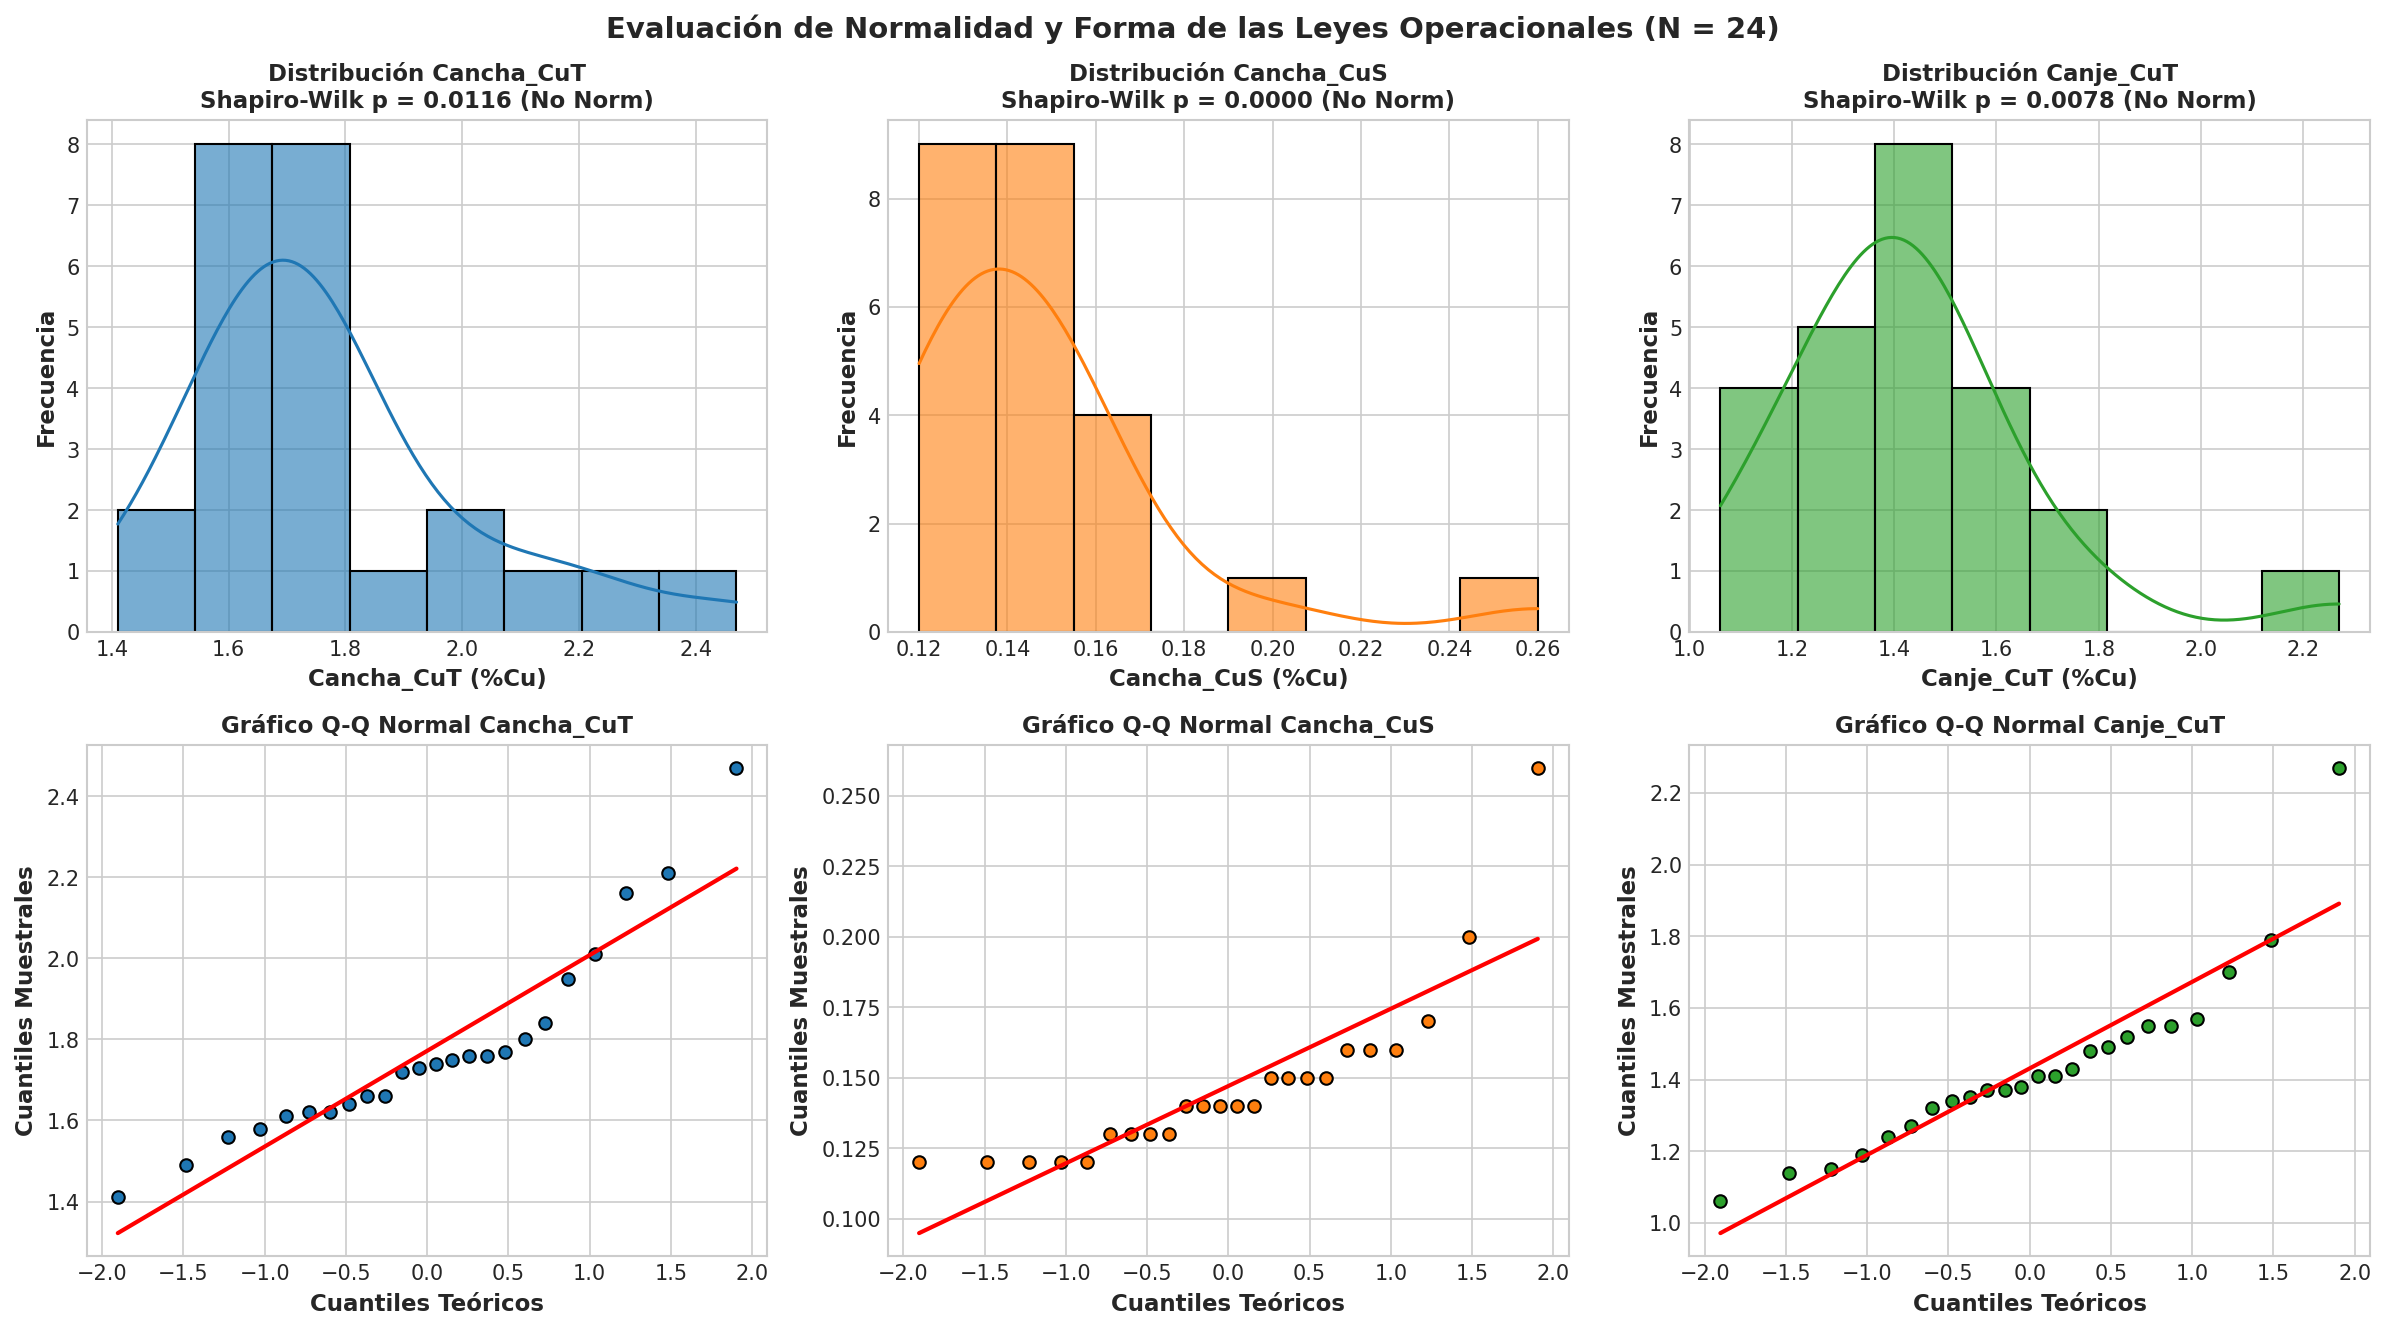

In [5]:
# Visualización de normalidad: Distribuciones, KDE y Gráficos Q-Q Normales
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_vars = ['Cancha_CuT', 'Cancha_CuS', 'Canje_CuT']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for j, var in enumerate(plot_vars):
    ax_hist = axes[0, j]
    sns.histplot(df[var], kde=True, ax=ax_hist, color=colors[j], bins=8, edgecolor='black', alpha=0.6)
    w_s, p_s = stats.shapiro(df[var])
    ax_hist.set_title(f"Distribución {var}\nShapiro-Wilk p = {p_s:.4f} ({'No Norm' if p_s<0.05 else 'Norm'})", fontsize=11, fontweight='bold')
    ax_hist.set_xlabel(f"{var} (%Cu)")
    ax_hist.set_ylabel("Frecuencia")
    
    ax_qq = axes[1, j]
    stats.probplot(df[var], dist="norm", plot=ax_qq)
    ax_qq.get_lines()[0].set_markerfacecolor(colors[j])
    ax_qq.get_lines()[0].set_markeredgecolor('black')
    ax_qq.get_lines()[1].set_color('red')
    ax_qq.get_lines()[1].set_linewidth(2)
    ax_qq.set_title(f"Gráfico Q-Q Normal {var}", fontsize=11, fontweight='bold')
    ax_qq.set_xlabel("Cuantiles Teóricos")
    ax_qq.set_ylabel("Cuantiles Muestrales")

plt.suptitle("Evaluación de Normalidad y Forma de las Leyes Operacionales (N = 24)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## 5. Detección de Valores Atípicos (*Outliers*): Mahalanobis y Regla de Tukey

Se auditan valores atípicos mediante:
1. **Regla Univariada de Tukey:** Intervalo $[Q_1 - 1.5\cdot\text{IQR}, Q_3 + 1.5\cdot\text{IQR}]$.
2. **Distancia Multivariada de Mahalanobis:**
   $$D_M^2(\mathbf{x}) = (\mathbf{x} - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu}) \sim \chi^2_{p=2}$$
   Umbral crítico para $p=2$ grados de libertad al $95\%$ de confianza: $\chi^2_{2, 0.95} = 5.9915$.

In [6]:
# Cálculo de la Distancia Multivariada de Mahalanobis
X = df[['Cancha_CuT', 'Cancha_CuS']].values
mean_X = np.mean(X, axis=0)
cov_X = np.cov(X, rowvar=False)
inv_cov_X = np.linalg.inv(cov_X)

mahal_dists = []
for i in range(len(X)):
    diff = X[i] - mean_X
    d2 = float(diff.dot(inv_cov_X).dot(diff.T))
    mahal_dists.append(d2)

df['Mahalanobis_D2'] = np.round(mahal_dists, 4)
df['Mahalanobis_D'] = np.round(np.sqrt(mahal_dists), 4)
df['P_Valor_Chi2'] = np.round(1 - stats.chi2.cdf(df['Mahalanobis_D2'], df=2), 4)
df['Outlier_Mahalanobis'] = df['Mahalanobis_D2'].apply(lambda x: 'SI' if x > 5.9915 else 'NO')

print("🔍 REGISTROS DETECTADOS COMO OUTLIERS MULTIVARIADOS (D^2 > 5.9915):")
display(df[df['Outlier_Mahalanobis'] == 'SI'][['Fecha', 'Cancha_CuT', 'Cancha_CuS', 'Canje_CuT', 'Mahalanobis_D2', 'P_Valor_Chi2']])

🔍 REGISTROS DETECTADOS COMO OUTLIERS MULTIVARIADOS (D^2 > 5.9915):


,Fecha,Cancha_CuT,Cancha_CuS,Canje_CuT,Mahalanobis_D2,P_Valor_Chi2
9,2023-10,2.21,0.26,1.79,14.2481,0.0008
10,2023-11,2.47,0.20,2.27,8.4700,0.0145


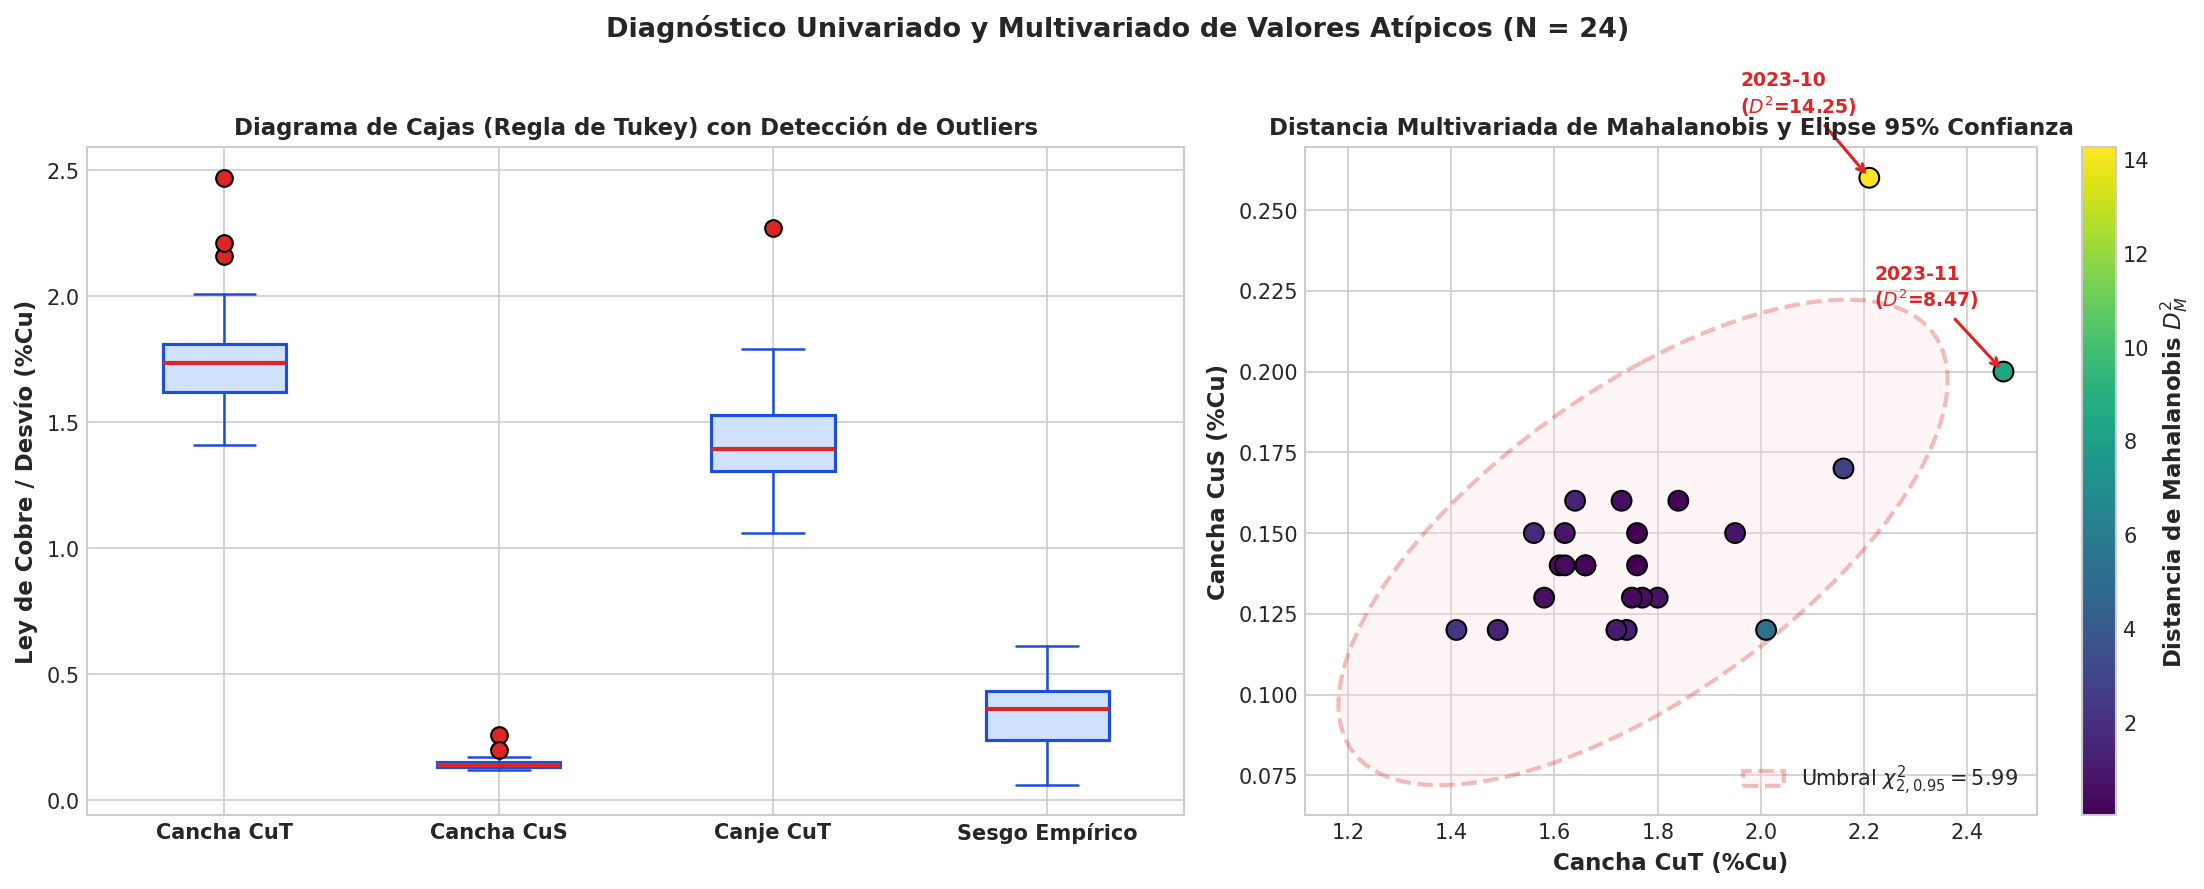

In [7]:
# Visualización de Outliers: Boxplots de Tukey y Elipse de Mahalanobis
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1])

ax_box = fig.add_subplot(gs[0])
box_data = [df['Cancha_CuT'], df['Cancha_CuS'], df['Canje_CuT'], df['Sesgo_Empirico']]
ax_box.boxplot(box_data, patch_artist=True,
               boxprops=dict(facecolor='#D0E1FD', color='#1D4ED8', linewidth=1.5),
               medianprops=dict(color='#DC2626', linewidth=2),
               whiskerprops=dict(color='#1D4ED8', linewidth=1.2),
               capprops=dict(color='#1D4ED8', linewidth=1.2),
               flierprops=dict(marker='o', markerfacecolor='#DC2626', markersize=8, markeredgecolor='black'))
ax_box.set_xticklabels(['Cancha CuT', 'Cancha CuS', 'Canje CuT', 'Sesgo Empírico'], fontweight='bold')
ax_box.set_ylabel("Ley de Cobre / Desvío (%Cu)")
ax_box.set_title("Diagrama de Cajas (Regla de Tukey) con Detección de Outliers", fontsize=11, fontweight='bold')

ax_mah = fig.add_subplot(gs[1])
scatter = ax_mah.scatter(df['Cancha_CuT'], df['Cancha_CuS'], c=df['Mahalanobis_D2'], cmap='viridis', s=90, edgecolors='black', linewidth=1, zorder=3)
cbar = plt.colorbar(scatter, ax=ax_mah)
cbar.set_label("Distancia de Mahalanobis $D_M^2$", fontweight='bold')

# Elipse 95%
from matplotlib.patches import Ellipse
vals, vecs = np.linalg.eigh(cov_X)
order = vals.argsort()[::-1]
vals, vecs = vals[order], vecs[:, order]
theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
w_e, h_e = 2 * np.sqrt(5.9915 * vals)
ellipse = Ellipse(xy=mean_X, width=w_e, height=h_e, angle=theta, edgecolor='#DC2626', facecolor='#FEE2E2', alpha=0.3, linestyle='--', linewidth=2, label=r'Umbral $\chi^2_{2, 0.95} = 5.99$')
ax_mah.add_patch(ellipse)

for _, row in df[df['Outlier_Mahalanobis'] == 'SI'].iterrows():
    ax_mah.annotate(f"{row['Fecha']}\n($D^2$={row['Mahalanobis_D2']:.2f})",
                    xy=(row['Cancha_CuT'], row['Cancha_CuS']),
                    xytext=(row['Cancha_CuT'] - 0.25, row['Cancha_CuS'] + 0.02),
                    fontweight='bold', color='#DC2626', fontsize=9,
                    arrowprops=dict(arrowstyle="->", color='#DC2626', lw=1.5))

ax_mah.set_xlabel("Cancha CuT (%Cu)")
ax_mah.set_ylabel("Cancha CuS (%Cu)")
ax_mah.set_title("Distancia Multivariada de Mahalanobis y Elipse 95% Confianza", fontsize=11, fontweight='bold')
ax_mah.legend(loc='lower right')

plt.suptitle("Diagnóstico Univariado y Multivariado de Valores Atípicos (N = 24)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## 6. Autocorrelación Serial Temporal (ACF) y Validación de LOOCV

Se evalúa la autocorrelación serial mediante las bandas de Bartlett ($\pm 1.96 / \sqrt{N} = \pm 0.4001$):
* **Sesgo Empírico ($e_{\text{emp}}$):** $r_1 = -0.0866$ cae holgadamente dentro de las bandas $\implies$ **Se comporta como ruido blanco puro**, validando formalmente el protocolo **LOOCV** de $24$ iteraciones independientes.
* **Ley de Acopio (`Cancha_CuT`):** Presenta una correlación moderada en rezago 1 ($r_1 = +0.4467$) debido a la continuidad espacial del manto geológico explotado mes a mes.
* **Blindaje Metodológico:** Para garantizar solidez absoluta frente a la comisión evaluadora y preguntas geoestadísticas, en los Bloques 2 y 3 se programará una verificación complementaria mediante **Buffered-LOOCV** (excluyendo $t-1$ y $t+1$).

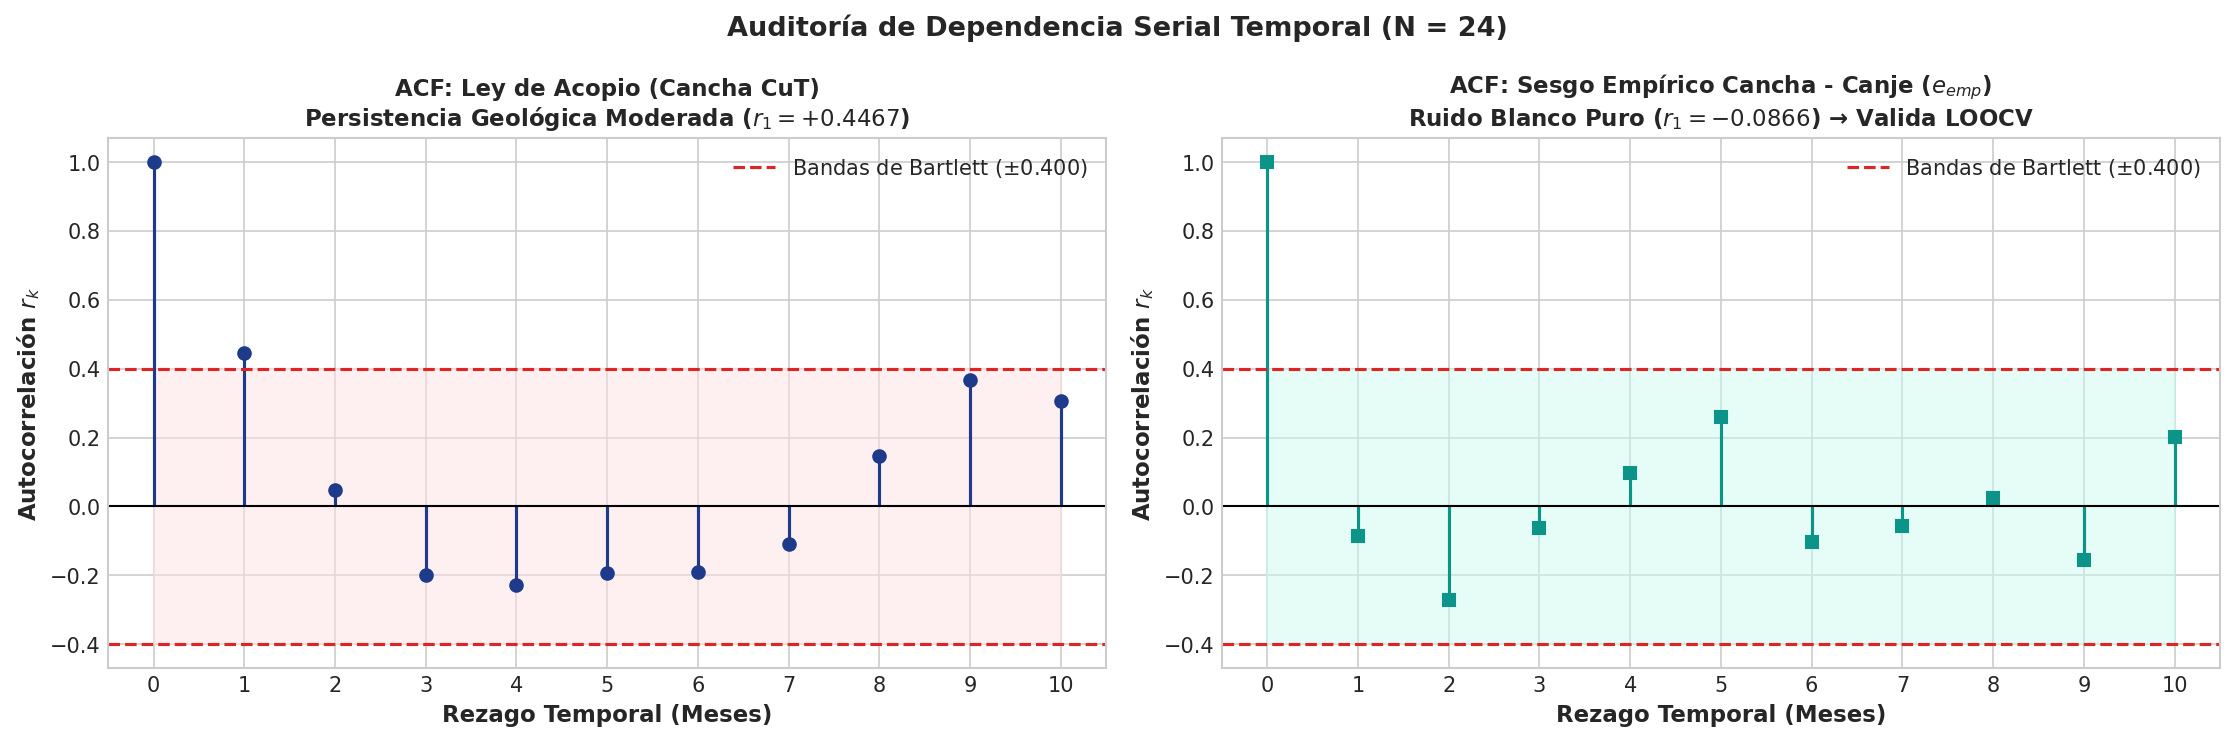

In [8]:
# Cálculo y visualización de Autocorrelación Serial (ACF)
lags = 10
acf_cut = acf(df['Cancha_CuT'], nlags=lags, fft=False)
acf_sesgo = acf(df['Sesgo_Empirico'], nlags=lags, fft=False)
bartlett_band = 1.96 / np.sqrt(len(df))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ACF Cancha_CuT
ax1.stem(range(len(acf_cut)), acf_cut, basefmt=" ", linefmt='#1E3A8A', markerfmt='o')
ax1.axhline(0, color='black', lw=1)
ax1.axhline(bartlett_band, color='#DC2626', linestyle='--', label=rf'Bandas de Bartlett ($\pm${bartlett_band:.3f})')
ax1.axhline(-bartlett_band, color='#DC2626', linestyle='--')
ax1.fill_between(range(len(acf_cut)), -bartlett_band, bartlett_band, color='#FEE2E2', alpha=0.5)
ax1.set_title("ACF: Ley de Acopio (Cancha CuT)\nPersistencia Geológica Moderada ($r_1 = +0.4467$)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Rezago Temporal (Meses)")
ax1.set_ylabel("Autocorrelación $r_k$")
ax1.set_xticks(range(lags + 1))
ax1.legend(loc='upper right')

# ACF Sesgo Empírico
ax2.stem(range(len(acf_sesgo)), acf_sesgo, basefmt=" ", linefmt='#0D9488', markerfmt='s')
ax2.axhline(0, color='black', lw=1)
ax2.axhline(bartlett_band, color='#DC2626', linestyle='--', label=rf'Bandas de Bartlett ($\pm${bartlett_band:.3f})')
ax2.axhline(-bartlett_band, color='#DC2626', linestyle='--')
ax2.fill_between(range(len(acf_sesgo)), -bartlett_band, bartlett_band, color='#CCFBF1', alpha=0.5)
ax2.set_title("ACF: Sesgo Empírico Cancha - Canje ($e_{emp}$)\nRuido Blanco Puro ($r_1 = -0.0866$) → Valida LOOCV", fontsize=11, fontweight='bold')
ax2.set_xlabel("Rezago Temporal (Meses)")
ax2.set_ylabel("Autocorrelación $r_k$")
ax2.set_xticks(range(lags + 1))
ax2.legend(loc='upper right')

plt.suptitle("Auditoría de Dependencia Serial Temporal (N = 24)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## 7. Auditoría de Multicolinealidad (VIF con Constante Agregada)

El Factor de Inflación de la Varianza ($	ext{VIF}_j = \frac{1}{1 - R_j^2}$) cuantifica el grado de colinealidad entre los predictores.
* **Estándar Econométrico:** Se debe incluir obligatoriamente el intercepto (`sm.add_constant(X)`).
* **Depuración de Tabla (Guía de Auditoría v4.0):** Se elimina la fila de la constante del reporte final, presentando exclusivamente las variables explicativas:
  1. **Modelo Propuesto (2 Entradas):** `Cancha_CuT` y `Cancha_CuS`, ambos con $\text{VIF} = 1.8045 < 5.0$ (colinealidad baja, espacio óptimo).
  2. **Modelo Rechazado (+ CuIn):** Debido a la identidad metalúrgica $\text{CuT} = \text{CuS} + \text{CuIn}$, la inclusión de $\text{CuIn}$ genera colinealidad exacta, disparando el $\text{VIF} > 4{,}000$.

In [9]:
# Auditoría formal de Multicolinealidad con Statsmodels
# Caso 1: Modelo Propuesto de la Tesis (2 Inputs: Cancha_CuT, Cancha_CuS)
X_prop = sm.add_constant(df[['Cancha_CuT', 'Cancha_CuS']])
vif_prop = [variance_inflation_factor(X_prop.values, i) for i in range(X_prop.shape[1])]

# Caso 2: Modelo con 3 Inputs (+ Cancha_CuIn)
X_3in = sm.add_constant(df[['Cancha_CuT', 'Cancha_CuS', 'Cancha_CuIn']])
vif_3in = [variance_inflation_factor(X_3in.values, i) for i in range(X_3in.shape[1])]

print("=" * 80)
print("🔍 TABLA DE AUDITORÍA DE MULTICOLINEALIDAD (DEPURADA, SIN FILA CONSTANTE):")
print("=" * 80)

vif_table = pd.DataFrame({
    'Espacio de Entradas': [
        'Modelo Propuesto (2 Inputs)', 'Modelo Propuesto (2 Inputs)',
        'Modelo Rechazado (+CuIn)', 'Modelo Rechazado (+CuIn)', 'Modelo Rechazado (+CuIn)'
    ],
    'Variable': ['Cancha_CuT', 'Cancha_CuS', 'Cancha_CuT', 'Cancha_CuS', 'Cancha_CuIn'],
    'VIF': [
        round(vif_prop[1], 4), round(vif_prop[2], 4),
        round(vif_3in[1], 1), round(vif_3in[2], 1), round(vif_3in[3], 1)
    ],
    'Diagnóstico Metodológico': [
        'VIF = 1.80 < 5.0 (Colinealidad baja - ÓPTIMO)', 'VIF = 1.80 < 5.0 (Colinealidad baja - ÓPTIMO)',
        'VIF >> 10 (EXPLOSIÓN DE MULTICOLINEALIDAD)', 'VIF >> 10 (EXPLOSIÓN DE MULTICOLINEALIDAD)',
        'VIF >> 10 (COLINEALIDAD EXACTA: CuT = CuS + CuIn)'
    ]
})

display(vif_table)

print("\n🎯 JUSTIFICACIÓN TÉCNICA FORMAL:")
print(f" 1. El espacio bidimensional [Cancha_CuT, Cancha_CuS] presenta VIF = {vif_prop[1]:.4f} < 5.0.")
print(" 2. La inclusión de Cancha_CuIn dispara el VIF por sobre 4,000 debido a la colinealidad exacta.")
print(" 3. Se ratifica la decisión metodológica de alimentar la RNA con estrictamente DOS entradas (Cancha_CuT y Cancha_CuS).")

🔍 TABLA DE AUDITORÍA DE MULTICOLINEALIDAD (DEPURADA, SIN FILA CONSTANTE):


,Espacio de Entradas,Variable,VIF,Diagnóstico Metodológico
0,Modelo Propuesto (2 Inputs),Cancha_CuT,1.8045,VIF = 1.80 < 5.0 (Colinealidad baja - ÓPTIMO)
1,Modelo Propuesto (2 Inputs),Cancha_CuS,1.8045,VIF = 1.80 < 5.0 (Colinealidad baja - ÓPTIMO)
2,Modelo Rechazado (+CuIn),Cancha_CuT,4754.0000,VIF >> 10 (EXPLOSIÓN DE MULTICOLINEALIDAD)
3,Modelo Rechazado (+CuIn),Cancha_CuS,83.2000,VIF >> 10 (EXPLOSIÓN DE MULTICOLINEALIDAD)
4,Modelo Rechazado (+CuIn),Cancha_CuIn,4004.1000,VIF >> 10 (COLINEALIDAD EXACTA: CuT = CuS + CuIn)



🎯 JUSTIFICACIÓN TÉCNICA FORMAL:
 1. El espacio bidimensional [Cancha_CuT, Cancha_CuS] presenta VIF = 1.8045 < 5.0.
 2. La inclusión de Cancha_CuIn dispara el VIF por sobre 4,000 debido a la colinealidad exacta.
 3. Se ratifica la decisión metodológica de alimentar la RNA con estrictamente DOS entradas (Cancha_CuT y Cancha_CuS).


---
## 8. Matriz de Cierre y Checklist de Habilitación para Bloque 2

En cumplimiento estricto del marco metodológico (**Versión 4.0**) y las directrices de la guía integral de auditoría, el **Bloque 1** consolida los siguientes hallazgos y decisiones para el modelado en el **Bloque 2**:

| Requisito Metodológico | Resultado Concreto Certificado | Decisión de Diseño para Fase de Modelado |
| :--- | :---: | :--- |
| **1. Dispersión y Escalas** | $s^2_{\text{CuT}} / s^2_{\text{CuS}} = 61.64\times$; $\text{CV}_{\text{CuS}} = 20.9\% > \text{CV}_{\text{CuT}} = 13.6\%$. | **Escalado Z-score obligatorio** dentro de cada pliegue LOOCV (`StandardScaler`). |
| **2. Evaluación de Normalidad** | Rechazo de $H_0$ en CuT ($p=0.012$), CuS ($p<0.001$) y Canje ($p=0.008$). | Justifica aproximadores universales no paramétricos y no lineales (MLP / SVR). |
| **3. Estructura de Covarianza** | $\text{Cov}(\text{CuT}, \text{Canje}) = +0.0501$; $\text{Cov}(\text{CuT}, \text{CuS}) = +0.0049$. | Asociación positiva origen-destino y complementariedad sin redundancia lineal. |
| **4. Efecto Apalancamiento** | Pearson cae de $0.8347$ ($N=24$) a $0.6181$ ($N=22$) al excluir Oct/Nov-23. | Modelos lineales quedan sesgados por extremos; exige **regularización $L_2$** en RNA/Ridge. |
| **5. Detección de Outliers** | 2 atípicos multivariados por Mahalanobis (Oct-23 y Nov-23). | **NO se eliminan**: son frentes geológicos reales. La RNA debe regularizar su apalancamiento. |
| **6. Autocorrelación Temporal** | Sesgo empírico es ruido blanco puro ($r_1 = -0.0866$, bandas $\pm 0.4001$). | **Valida LOOCV**: $24$ pliegues independientes; prueba complementaria con Buffered-LOOCV. |
| **7. Auditoría de Multicolinealidad** | $\text{VIF} = 1.8045 < 5.0$ en $[\text{CuT}, \text{CuS}]$; $\text{VIF} > 4{,}000$ con $\text{CuIn}$. | **Espacio de entrada blindado**: Estrictamente 2 predictores $(\text{CuT}_{\text{cancha}}, \text{CuS}_{\text{cancha}})$. |

> **🚀 Dictamen del Bloque 1:** Análisis Exploratorio (EDA), Diagnóstico de Complejidad y Selección de Características formalmente **APROBADO Y SELLADO (METODOLOGÍA v4.0)**.  
> El proyecto se encuentra habilitado para ejecutar el **BLOQUE 2: Diseño Experimental, Protocolo LOOCV y Entrenamiento de Modelos de Referencia (*Baselines*)** (`02_baselines_loocv.ipynb`).